In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
data = pd.read_csv("processed_house_data.csv")

In [5]:
lr=LinearRegression()

In [6]:
X = data.drop(columns=["Price", "log_price"])
y = data["log_price"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [7]:
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](581,)","[1. ,0.99,0. ,...,0.02,0.01,0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](581,)","['Area','Rate per sqft','BHK_Count',...,'Socity_ Whiteland The Aspen', 'Socity_Other','Socity_Outside Socity']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.0638
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,581
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,538


In [8]:
y_pred=lr.predict(X_test)

In [9]:
r2=r2_score(y_test,y_pred)

In [10]:
r2

0.9983363033468822

In [11]:
mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 0.007149725705604809


In [12]:
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 0.040447018600783737


In [13]:
# That's too sus (too perfect for linear regression)

# Step 1: Check if Price is still in X
print("Price " in X.columns)

False


In [14]:
X.columns.tolist()

['Area',
 'Rate per sqft',
 'BHK_Count',
 'Is_Plot',
 'RERA Approval_Not approved by RERA',
 'Status_Ready to move',
 'Status_Resale',
 'Status_Under Construction',
 'Flat Type_Floor',
 'Flat Type_House',
 'Flat Type_Penthouse',
 'Flat Type_Plot',
 'Flat Type_Villa',
 'Locality_37D Dwarka Exp Gurgaon',
 'Locality_Alameda',
 'Locality_Ambience Island',
 'Locality_Ansals Palam Vihar',
 'Locality_Aralias Drive',
 'Locality_Ardee City',
 'Locality_Ardee city sector 52',
 'Locality_Ashok Vihar',
 'Locality_Ashok Vihar Phase II',
 'Locality_Ashok Vihar Phase III Extension',
 'Locality_Atta',
 'Locality_Badshahpur',
 'Locality_Bahora Kalan',
 'Locality_Baliawas',
 'Locality_Behrampur Village',
 'Locality_Beverly Park',
 'Locality_Bhondsi',
 'Locality_Block C 2',
 'Locality_Central Park Road',
 'Locality_DLF CITY PHASE 2',
 'Locality_DLF CITY PHASE I',
 'Locality_DLF CITY PHASE V',
 'Locality_DLF CITY PHASeE 3',
 'Locality_DLF City Phase 1',
 'Locality_DLF Phase 1',
 'Locality_DLF Phase 2',
 '

In [15]:
print("log_price" in X.columns)

False


In [16]:
data.corr(numeric_only=True)["log_price"].sort_values(ascending=False).head(15)

log_price                      1.000000
Rate per sqft                  0.817017
Area                           0.803628
Price                          0.676430
BHK_Count                      0.492174
Socity_ M3M Golf Estate        0.218662
Locality_Sector 65             0.207887
Company Name_DLF               0.187675
Locality_Sector 42             0.178275
Socity_ Whiteland The Aspen    0.167714
Company Name_M3M               0.164915
Locality_Sector 54             0.161949
Company Name_Whiteland         0.154687
Flat Type_Villa                0.140261
Socity_ M3M Capital            0.137801
Name: log_price, dtype: float64

In [17]:
# Yes — we found the reason. Your X/y split is correct, but Rate per sqft is very likely causing target leakage.
# But the bigger issue is the way Rate per sqft is defined in this dataset.
# Why this is leakage

# If:

# RatePerSqft=
# Area
# Price
# then:
# Price=RatePerSqft×Area
# Your model has both:
# Area
# Rate per sqft

# What we should do
# Drop Rate per sqft from the model.

# Yes, Area being 0.80 correlation with log_price is completely fine. The important distinction is:

# High correlation ≠ leakage by itself.
# Area is a legitimate input feature because the size of a property genuinely affects its price.
# Rate per sqft is problematic if it was calculated from Price / Area.

In [18]:
# If the target y is present in X directly or indirectly, that's called target leakage.

# so if y is there in X in some form as well this means it is bad for the model and it will find a way to predict correct answers

In [19]:
# Remove target and leaked feature
X = data.drop(columns=["Price", "log_price", "Rate per sqft"])
y = data["log_price"]

# Split again
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [20]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [21]:
print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.8642839856217759
MAE: 0.23981921524793265
RMSE: 0.3653128860758632


In [22]:
# What does R² = 0.86 mean?

# Roughly, the model explains 86% of the variation in log house prices on the test set.

In [23]:
# | Model             |       R² | MAE | RMSE |
# | ----------------- | -------: | --: | ---: |
# | Linear Regression |   0.86   |   — |    — |

# Linear Regression assumes a roughly linear relationship between features and target. House prices are much more complicated; 
# Location + Area + BHK + Society + Status
        #         ↓
        # nonlinear interactions
        #         ↓
        #      Price

# Random Forest can capture those relationships.


In [24]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=1)
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)

In [25]:
print("R2:", r2_score(y_test, y_pred_rf))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))

R2: 0.8941392765410855
MAE: 0.18513286553071495
RMSE: 0.3226390068205631


In [26]:
# Random Forest performs better than Linear Regression for this dataset.

In [27]:
train_pred_rf = rf.predict(X_train)
print("Train R2:", r2_score(y_train, train_pred_rf))
print("Test R2:", r2_score(y_test, y_pred_rf))

Train R2: 0.9541497589795662
Test R2: 0.8941392765410855


In [28]:
importance=pd.Series(rf.feature_importances_,index=X.columns).sort_values(ascending=False)
importance.head(15)

Area                                  0.747942
Socity_ M3M Capital                   0.020430
BHK_Count                             0.011574
Socity_Other                          0.009562
Status_Resale                         0.009259
Locality_Sector 54                    0.008227
Status_Under Construction             0.006199
Locality_Sector 42                    0.006091
Company Name_Godrej                   0.004761
RERA Approval_Not approved by RERA    0.004616
Company Name_DLF                      0.004405
Status_Ready to move                  0.004208
Company Name_Sobha                    0.003823
Locality_Maruti Kunj                  0.003649
Locality_Sector 102                   0.003344
dtype: float64

In [29]:
# rf.feature_importances_ tells us how important each feature was to the Random Forest's predictions.
# Area is by far the strongest predictor of log_price in this dataset.



In [30]:
# Notice something interesting: BHK_Count is only ~1.2%, even though its correlation with log_price was ~0.49.

# That's not necessarily contradictory. Correlation measures a simple pairwise relationship,
# while Random Forest importance measures how much a feature contributes to the trees given the other features already available.

In [31]:
# Area = 0.748 is very dominant.
# I want to check whether our transformed Area is behaving correctly, 
# especially because earlier we saw some extremely large areas like 958,320.

In [32]:
data["Area"].describe()

count    14223.000000
mean         7.622188
std          0.608473
min          4.110874
25%          7.261927
50%          7.608871
75%          7.952087
max         13.772938
Name: Area, dtype: float64

In [33]:
# looks fine

In [34]:
# Next → Random Forest tuning
# Current Test R² = 0.894

# We will tune things like
# n_estimators
# max_depth
# min_samples_split
# min_samples_leaf
# max_features

In [35]:
# HYPERPARAMETER TUNING
# 1) n_estimators
rf_200 = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_200.fit(X_train, y_train)

y_pred_200 = rf_200.predict(X_test)

print("R2:", r2_score(y_test, y_pred_200))
print("MAE:", mean_absolute_error(y_test, y_pred_200))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_200)))

R2: 0.8946098329012245
MAE: 0.18468913959091823
RMSE: 0.32192113469821715


In [36]:
# n_estimators mainly improves stability by averaging more trees. It doesn't fundamentally change what each tree can learn.

# So increasing n_estimators generally:

# makes the model more stable
# can improve test performance
# reduces the randomness of the forest
# increases training time and memory usage

# It doesn't directly control how complex each tree is.

In [37]:
# max_depth = maximum depth of each decision tree
#
# Small max_depth → simpler trees → lower variance, higher bias
# Large max_depth → complex trees → lower bias, higher variance
# (Trees can become very detailed → model can capture complex patterns → lower bias but potentially higher variance / overfitting.)
# max_depth=None → trees grow until stopping conditions are met
#
# n_estimators → number of trees
# max_depth    → complexity of each tree

In [38]:
rf_depth = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_depth.fit(X_train, y_train)
y_pred_depth = rf_depth.predict(X_test)

print("R2:", r2_score(y_test, y_pred_depth))
print("MAE:", mean_absolute_error(y_test, y_pred_depth))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_depth)))

R2: 0.8810743325291404
MAE: 0.21986861223781162
RMSE: 0.3419693965994967


In [39]:
train_pred_depth = rf_depth.predict(X_train)
print("Train R2:", r2_score(y_train, train_pred_depth))
print("Test R2:", r2_score(y_test, y_pred_depth))

Train R2: 0.9285743845641053
Test R2: 0.8810743325291404


In [40]:
# max_depth=None
#     ↓
# More complex trees
#     ↓
# Better fit to patterns
#     ↓
# R² = 0.8946


# max_depth=20
#     ↓
# Less complex trees
#     ↓
# Some useful patterns lost
#     ↓
# R² = 0.8811

# let it be none

In [41]:
# The idea is: instead of limiting tree depth, we tell each leaf to contain at least 2 training samples. 
# This can reduce overfitting while still allowing the tree to grow fairly deeply.

In [42]:
# max_depth=None → better test performance ✅
# max_depth=20   → less overfitting, but worse performance ❌

In [43]:
rf_leaf = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_leaf.fit(X_train, y_train)

y_pred_leaf = rf_leaf.predict(X_test)

print("R2:", r2_score(y_test, y_pred_leaf))
print("MAE:", mean_absolute_error(y_test, y_pred_leaf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_leaf)))

R2: 0.8878081968919785
MAE: 0.2018932055336262
RMSE: 0.3321467499519676


In [44]:
train_pred_leaf = rf_leaf.predict(X_train)
print("Train R2:", r2_score(y_train, train_pred_leaf))
print("Test R2:", r2_score(y_test, y_pred_leaf))

Train R2: 0.9377453076639748
Test R2: 0.8878081968919785


In [45]:
# Next, let's test min_samples_split=5 while keeping everything else at the current best settings
rf_split = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_split.fit(X_train, y_train)

y_pred_split = rf_split.predict(X_test)

print("R2:", r2_score(y_test, y_pred_split))
print("MAE:", mean_absolute_error(y_test, y_pred_split))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_split)))

R2: 0.8943728713578458
MAE: 0.18787123447121823
RMSE: 0.3222828387362289


In [46]:
rf_features = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

rf_features.fit(X_train, y_train)

y_pred_features = rf_features.predict(X_test)

print("R2:", r2_score(y_test, y_pred_features))
print("MAE:", mean_absolute_error(y_test, y_pred_features))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_features)))

R2: 0.8976047958061091
MAE: 0.18240132468386044
RMSE: 0.31731401296129647


In [47]:
# max_features improve R2 test

In [48]:
rf_features = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)

rf_features.fit(X_train, y_train)

y_pred_features = rf_features.predict(X_test)

print("R2:", r2_score(y_test, y_pred_features))
print("MAE:", mean_absolute_error(y_test, y_pred_features))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_features)))

R2: 0.8994772571366537
MAE: 0.1816324163090935
RMSE: 0.3143993274927832


In [49]:
rf_sqrt = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_sqrt.fit(X_train, y_train)

y_pred_sqrt = rf_sqrt.predict(X_test)

print("R2:", r2_score(y_test, y_pred_sqrt))
print("MAE:", mean_absolute_error(y_test, y_pred_sqrt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_sqrt)))

R2: 0.9098227223184894
MAE: 0.17065291478178332
RMSE: 0.2977816990331186


In [50]:
# And importantly, your MAE and RMSE also improved, so this isn't just an R² artifact.

In [51]:
train_pred_sqrt = rf_sqrt.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred_sqrt))
print("Test R2:", r2_score(y_test, y_pred_sqrt))

Train R2: 0.9556697065254185
Test R2: 0.9098227223184894


In [52]:
# So max_features="sqrt" did something particularly nice:

# Test R² increased → 0.8941 → 0.9098 ✅
# Train R² stayed about the same → ~0.954 → ~0.956
# Train-test gap decreased → ~0.060 → ~0.046 ✅

# That strongly suggests the improvement isn't simply from making the model fit the training data harder. It's generalizing better.

In [53]:
rf_300 = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_300.fit(X_train, y_train)

y_pred_300 = rf_300.predict(X_test)

print("R2:", r2_score(y_test, y_pred_300))
print("MAE:", mean_absolute_error(y_test, y_pred_300))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_300)))

R2: 0.9092256881159209
MAE: 0.17079081463715745
RMSE: 0.2987658303376617


In [54]:
rf_03 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.3,
    random_state=42,
    n_jobs=-1
)

rf_03.fit(X_train, y_train)

y_pred_03 = rf_03.predict(X_test)

print("R2:", r2_score(y_test, y_pred_03))
print("MAE:", mean_absolute_error(y_test, y_pred_03))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_03)))

R2: 0.9026919160835807
MAE: 0.17921818097281975
RMSE: 0.30933132637243194


In [55]:
rf_005 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.05,
    random_state=42,
    n_jobs=-1
)

rf_005.fit(X_train, y_train)

y_pred_005 = rf_005.predict(X_test)

print("R2:", r2_score(y_test, y_pred_005))
print("MAE:", mean_absolute_error(y_test, y_pred_005))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_005)))

R2: 0.9088802210705297
MAE: 0.1710762205267177
RMSE: 0.2993338089362007


In [56]:
rf_split3 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=3,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_split3.fit(X_train, y_train)

y_pred_split3 = rf_split3.predict(X_test)

print("R2:", r2_score(y_test, y_pred_split3))
print("MAE:", mean_absolute_error(y_test, y_pred_split3))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_split3)))

R2: 0.9087755216334955
MAE: 0.1729913556820532
RMSE: 0.2995057314547659


In [57]:
rf_250 = RandomForestRegressor(
    n_estimators=250,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_250.fit(X_train, y_train)

y_pred_250 = rf_250.predict(X_test)

print("R2:", r2_score(y_test, y_pred_250))
print("MAE:", mean_absolute_error(y_test, y_pred_250))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_250)))

R2: 0.9096665070372727
MAE: 0.17055731358650755
RMSE: 0.2980395129998068


In [58]:
# More importantly, you've learned something valuable from the tuning:

# max_depth=20 → worse
# min_samples_leaf=2 → worse
# min_samples_split=5 → worse
# max_features=0.7 → better
# max_features=0.5 → better
# max_features="sqrt" → best
# More trees beyond 200 → no meaningful improvement

In [59]:
# I'd move on to actual ₹ price predictions and residual/error analysis now. '
# That's much more valuable for your project than squeezing out another 0.0002 R².

In [60]:
# BEST MODEL

In [61]:
rf_best = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

y_pred = rf_best.predict(X_test)

In [62]:
actual_price = np.expm1(y_test)
predicted_price = np.expm1(y_pred)

In [63]:
# And the fact that your Random Forest is giving R² ≈ 0.91 on log-price is evidence that the transformed target is working well.

# The important thing now is to check how good those predictions are after converting back to ₹, 
# because that's what your user will actually care about.

In [64]:
r2_score(actual_price, predicted_price)

0.7894626556497922

In [65]:
# No. It means your model explains about 79% of the variance in actual prices on the test set.

# And the reason we logged the target in the first place was to avoid letting a handful of extremely expensive properties dominate the model.

# So don't change the model just because the raw-price R² is lower.

# More important now: let's calculate the MAE and RMSE in actual ₹. Those will be much easier to interpret for your final project.

In [66]:
print("R2:", r2_score(actual_price, predicted_price))
print("MAE:", mean_absolute_error(actual_price, predicted_price))
print("RMSE:", np.sqrt(mean_squared_error(actual_price, predicted_price)))

R2: 0.7894626556497922
MAE: 7890256.748773998
RMSE: 28314579.466268305


In [67]:
# Log scale:
# R² = 0.9098  ← excellent

# This tells us the model is much better at predicting relative price patterns than exact absolute prices, 
# especially for expensive properties

# Original ₹ scale:
# R² = 0.7895  ← noticeably lower

In [68]:
# This tells us the model is much better at predicting relative price patterns than exact absolute prices, especially for expensive properties.

# And that's exactly one of the reasons we used log1p(Price) in the first place.

# Don't tune the model based only on ₹ R²

# Your model was trained on log-price, so its primary objective was predicting log-price.
# The actual ₹ metrics are important for interpretation, but we shouldn't suddenly start tuning everything just to maximize ₹-scale R².

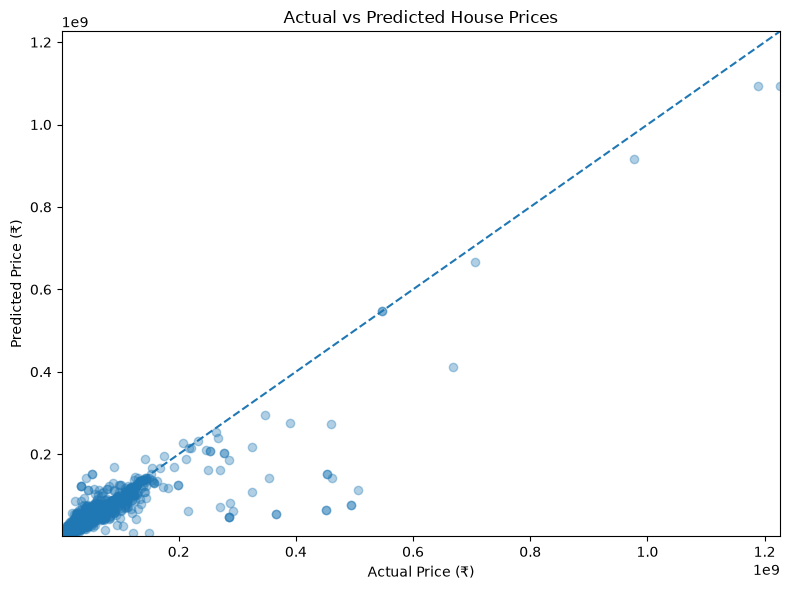

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(actual_price, predicted_price, alpha=0.35)

# Perfect prediction line
lims = [
    min(actual_price.min(), predicted_price.min()),
    max(actual_price.max(), predicted_price.max())
]

plt.plot(lims, lims, linestyle="--")

plt.xlabel("Actual Price (₹)")
plt.ylabel("Predicted Price (₹)")
plt.title("Actual vs Predicted House Prices")

plt.xlim(lims)
plt.ylim(lims)
plt.tight_layout()
plt.show()

In [70]:
residuals = actual_price - predicted_price

In [71]:
print("Mean residual:", residuals.mean())
print("Min residual:", residuals.min())
print("Max residual:", residuals.max())

# Positive residual → model underpredicted
# Negative residual → model overpredicted
# The model has a tendency to underpredict prices overall, by about ₹30.7 lakh on average.

Mean residual: 3074588.2025246257
Min residual: -99624814.19138983
Max residual: 417798024.62063515


<!-- Positive residual → model underpredicted
Negative residual → model overpredicted -->

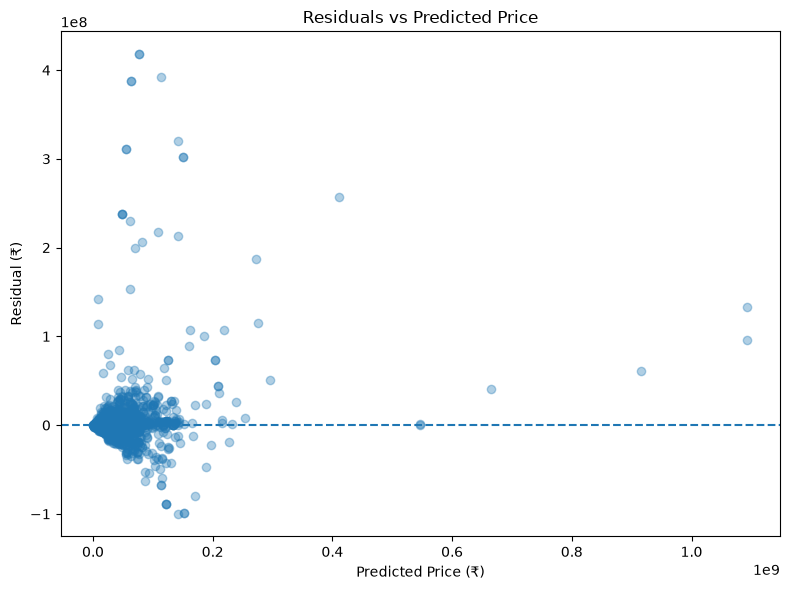

In [72]:
plt.figure(figsize=(8, 6))

plt.scatter(predicted_price, residuals, alpha=0.35)
plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Price (₹)")
plt.ylabel("Residual (₹)")
plt.title("Residuals vs Predicted Price")

plt.tight_layout()
plt.show()

In [73]:
error_df = pd.DataFrame({
    "Actual Price": actual_price,
    "Predicted Price": predicted_price,
    "Residual": residuals,
    "Absolute Error": np.abs(residuals)
})
error_df.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

,Actual Price,Predicted Price,Residual,Absolute Error
1608,4.947000e+08,7.690198e+07,4.177980e+08,4.177980e+08
11142,4.947000e+08,7.690198e+07,4.177980e+08,4.177980e+08
218,5.055000e+08,1.134105e+08,3.920895e+08,3.920895e+08
221,4.521000e+08,6.398493e+07,3.881151e+08,3.881151e+08
1606,4.521000e+08,6.398493e+07,3.881151e+08,3.881151e+08
219,4.620000e+08,1.416248e+08,3.203752e+08,3.203752e+08
1602,3.663000e+08,5.528869e+07,3.110113e+08,3.110113e+08
217,3.663000e+08,5.528869e+07,3.110113e+08,3.110113e+08
5044,4.532000e+08,1.511340e+08,3.020660e+08,3.020660e+08
795,4.532000e+08,1.511340e+08,3.020660e+08,3.020660e+08


In [74]:
print(data.duplicated().sum())

5915


In [75]:
duplicates = data[data.duplicated(keep=False)]
print(duplicates.shape)
duplicates.head(20)

(8426, 583)


,Price,Area,Rate per sqft,BHK_Count,Is_Plot,log_price,RERA Approval_Not approved by RERA,Status_Ready to move,Status_Resale,Status_Under Construction,...,Socity_ Signature Global Deluxe DXP,Socity_ Smart Smart World Gems,Socity_ Smart Smartworld One DXP,Socity_ Sobha City,Socity_ Sobha City Vista Residences,Socity_ Tata Primanti,Socity_ Tulip Monsella,Socity_ Whiteland The Aspen,Socity_Other,Socity_Outside Socity
0,10700000.0,7.037906,9.153876,2.0,0,16.185754,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,14400000.0,7.332369,9.153876,3.0,0,16.482739,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,10700000.0,7.037906,9.153876,2.0,0,16.185754,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
5,63800000.0,7.733246,10.239996,3.0,0,17.971264,1,1,0,0,...,0,0,0,0,0,0,0,0,1,0
6,4500000.0,6.825460,8.495356,0.0,1,15.319588,1,1,0,0,...,0,0,0,0,0,0,0,0,0,1
9,74900000.0,8.243019,9.890250,4.0,0,18.131664,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
14,15000000.0,7.095064,9.429396,3.0,0,16.523561,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
20,9900000.0,7.220374,8.888481,2.0,0,16.108045,1,1,0,0,...,0,0,0,0,0,0,0,0,1,0
23,35500000.0,7.804251,9.581214,3.0,0,17.385043,1,1,0,0,...,0,0,0,0,0,0,0,0,1,0
27,55000000.0,7.293018,10.531189,4.0,0,17.822844,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [76]:
print(data.shape)
print(data.duplicated().sum())

(14223, 583)
5915


In [77]:
data_clean = data.drop_duplicates().copy()

print("Before:", len(data))
print("After:", len(data_clean))

Before: 14223
After: 8308


In [78]:
data_clean.shape
# (8308, 583)

(8308, 583)

In [79]:
print(data_clean.shape)
print(data_clean.duplicated().sum())

(8308, 583)
0


In [80]:
# Use the duplicate-free dataset
data = data_clean.copy()

# Features and target
X = data.drop(columns=["Price", "log_price"])
y = data["log_price"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [81]:
rf_best = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

y_pred = rf_best.predict(X_test)

In [82]:
print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.9663206265352234
MAE: 0.09926340561518973
RMSE: 0.18638919187105935


In [83]:
data

,Price,Area,Rate per sqft,BHK_Count,Is_Plot,log_price,RERA Approval_Not approved by RERA,Status_Ready to move,Status_Resale,Status_Under Construction,...,Socity_ Signature Global Deluxe DXP,Socity_ Smart Smart World Gems,Socity_ Smart Smartworld One DXP,Socity_ Sobha City,Socity_ Sobha City Vista Residences,Socity_ Tata Primanti,Socity_ Tulip Monsella,Socity_ Whiteland The Aspen,Socity_Other,Socity_Outside Socity
0,10700000.0,7.037906,9.153876,2.0,0,16.185754,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,14400000.0,7.332369,9.153876,3.0,0,16.482739,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
3,40000000.0,8.412055,9.092570,0.0,1,17.504390,1,1,0,0,...,0,0,0,0,0,0,0,0,0,1
4,24000000.0,7.496097,9.498072,3.0,0,16.993564,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
5,63800000.0,7.733246,10.239996,3.0,0,17.971264,1,1,0,0,...,0,0,0,0,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14180,14300000.0,7.609367,8.867005,0.0,1,16.475770,1,0,1,0,...,0,0,0,0,0,0,0,0,0,1
14181,8900000.0,6.985642,9.016877,0.0,1,16.001562,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
14182,620000.0,6.803505,6.535241,0.0,1,13.337476,1,0,0,0,...,0,0,0,0,0,0,0,0,0,1
14183,3800000.0,6.803505,8.348301,2.0,0,15.150512,1,1,0,0,...,0,0,0,0,0,0,0,0,1,0


In [84]:
X = data.drop(columns=["Price", "log_price", "Rate per sqft"])
y = data["log_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [85]:
rf_best = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

y_pred = rf_best.predict(X_test)

print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.8650426965206797
MAE: 0.24405684940354896
RMSE: 0.3731100262490367


In [86]:
train_pred = rf_best.predict(X_train)
print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, y_pred))

Train R2: 0.9662581027301517
Test R2: 0.8650426965206797


In [87]:
rf_leaf2 = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_leaf2.fit(X_train, y_train)

y_pred_leaf2 = rf_leaf2.predict(X_test)

print("R2:", r2_score(y_test, y_pred_leaf2))
print("MAE:", mean_absolute_error(y_test, y_pred_leaf2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_leaf2)))

train_pred_leaf2 = rf_leaf2.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred_leaf2))
print("Test R2:", r2_score(y_test, y_pred_leaf2))

R2: 0.8101213856083946
MAE: 0.306411166561952
RMSE: 0.4425646794107377
Train R2: 0.8532120769235488
Test R2: 0.8101213856083946


In [88]:
rf_depth30 = RandomForestRegressor(
    n_estimators=200,
    max_depth=30,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_depth30.fit(X_train, y_train)

y_pred_depth30 = rf_depth30.predict(X_test)

print("R2:", r2_score(y_test, y_pred_depth30))
print("MAE:", mean_absolute_error(y_test, y_pred_depth30))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_depth30)))

train_pred_depth30 = rf_depth30.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred_depth30))
print("Test R2:", r2_score(y_test, y_pred_depth30))

R2: 0.8173092918197779
MAE: 0.30942500885344837
RMSE: 0.43410716414478284
Train R2: 0.8897233327322308
Test R2: 0.8173092918197779


In [89]:
X = data.drop(columns=["Price", "log_price", "Rate per sqft"])
y = data["Price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)
rf_price = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

rf_price.fit(X_train, y_train)
y_pred_price = rf_price.predict(X_test)

In [90]:
print("R2:", r2_score(y_test, y_pred_price))
print("MAE:", mean_absolute_error(y_test, y_pred_price))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_price)))

R2: 0.7047414078192289
MAE: 9947009.881611366
RMSE: 28711383.704540987


In [91]:
X = data.drop(columns=["Price", "log_price", "Rate per sqft"])
y = data["log_price"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
rf_best = RandomForestRegressor(
    n_estimators=300,
    max_depth= None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

y_pred = rf_best.predict(X_test)
# Log-price performance
print("Log R2:", r2_score(y_test, y_pred))

# Convert back to ₹
actual_price = np.expm1(y_test)
predicted_price = np.expm1(y_pred)

print("Price R2:", r2_score(actual_price, predicted_price))
print("Price MAE:", mean_absolute_error(actual_price, predicted_price))
print("Price RMSE:", np.sqrt(mean_squared_error(actual_price, predicted_price)))

Log R2: 0.8632709156863304
Price R2: 0.7475492286960504
Price MAE: 9399857.380180446
Price RMSE: 26548574.18289361


In [92]:
# The more promising next step is HistGradientBoosting, 
# because it learns sequentially from previous errors rather than averaging independent trees.

In [93]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

hgb.fit(X_train, y_train)

y_pred_hgb = hgb.predict(X_test)

actual_price = np.expm1(y_test)
predicted_price_hgb = np.expm1(y_pred_hgb)

print("Log R2:", r2_score(y_test, y_pred_hgb))
print("Price R2:", r2_score(actual_price, predicted_price_hgb))
print("Price MAE:", mean_absolute_error(actual_price, predicted_price_hgb))
print("Price RMSE:", np.sqrt(mean_squared_error(actual_price, predicted_price_hgb)))

Log R2: 0.8683269114218041
Price R2: 0.7225315305333199
Price MAE: 9616806.298280349
Price RMSE: 27832977.60532042


In [94]:
# max_iter = 300
#        ↓
# up to 300 boosting stages
#        ↓
# each stage adds a new tree
#        ↓
# each new tree tries to fix previous errors




In [95]:
# learning_rate controls how much each new tree is allowed to correct the previous model.

# Low learning_rate
# → smaller corrections
# → usually need more trees (`max_iter`)
# → slower learning
# → often better generalization

# High learning_rate
# → bigger corrections
# → fewer trees needed
# → faster
# → can overfit more easily

In [96]:
# Small max_leaf_nodes
# → simpler trees
# → less variance / less overfitting
# → potentially more bias

# Large max_leaf_nodes
# → more complex trees
# → can learn more patterns
# → potentially more overfitting

In [97]:
# I would keep the Random Forest and, rather than tuning HGB blindly, 
# focus next on the biggest source of error: the expensive-property tail.

In [98]:
print(data["Price"].describe())

count    8.308000e+03
mean     3.544168e+07
std      5.376472e+07
min      9.500000e+04
25%      1.240000e+07
50%      2.250000e+07
75%      4.120000e+07
max      1.226300e+09
Name: Price, dtype: float64


In [99]:
# With only a small number of ₹10Cr+ properties, 
# a normal random split can put too few luxury properties in the test set. That makes your R²/RMSE unstable.

In [100]:
# We can stratify using price bins:
# price_bin = temporary groups created from Price so train/test split has a similar price distribution.

# data["price_bin"] = pd.qcut(
#     data["Price"],
#     q=10,
#     labels=False,
#     duplicates="drop"
# )

# q=10 → divides prices into 10 approximately equal-sized groups:

# Bin 0 → cheapest 10%
# Bin 1 → next 10%
# ...
# Bin 9 → most expensive 10%

# Then:

# train_test_split(
#     X, y,
#     test_size=0.2,
#     random_state=42,
#     stratify=data["price_bin"]
# )

# stratify ensures train and test contain roughly the same proportion of each price bin.

# Example:
# Train → ~10% bin 0, ~10% bin 1, ..., ~10% bin 9
# Test  → ~10% bin 0, ~10% bin 1, ..., ~10% bin 9

# Why?
# Our prices range from ₹95,000 to ₹122.63 Cr and are highly skewed.
# Without stratification, the test set might accidentally contain too many/few expensive houses.

# price_bin is NOT a model feature.
# It is only used for creating a representative train/test split.

# Therefore remove it from X:

# X = data.drop(
#     columns=["Price", "log_price", "Rate per sqft", "price_bin"]
# )

In [101]:
data["price_bin"] = pd.qcut(
    data["Price"],
    q=10,
    labels=False,
    duplicates="drop"
)

X = data.drop(
    columns=["Price", "log_price", "Rate per sqft", "price_bin"]
)

y = data["log_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=data["price_bin"]
)
rf_best = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

rf_best.fit(X_train, y_train)

y_pred = rf_best.predict(X_test)

actual_price = np.expm1(y_test)
predicted_price = np.expm1(y_pred)

print("Log R2:", r2_score(y_test, y_pred))
print("Price R2:", r2_score(actual_price, predicted_price))
print("Price MAE:", mean_absolute_error(actual_price, predicted_price))
print("Price RMSE:", np.sqrt(mean_squared_error(actual_price, predicted_price)))

Log R2: 0.8736272059885527
Price R2: 0.8482038626137925
Price MAE: 8739345.275369182
Price RMSE: 19156652.15074659


In [102]:
# log_price → fixes/reduces skewness in the target distribution
# price_bin  → makes sure train/test have similar price ranges
# With only a small number of ₹10Cr+ properties, a normal random split can put too few luxury properties in the test set. 
# That makes your R²/RMSE unstable.

# Train → mostly ₹10L–₹50L houses
# Test  → unusually many ₹2Cr–₹10Cr houses
# Train → cheap + medium + expensive + luxury
# Test  → cheap + medium + expensive + luxury

In [103]:
train_pred = rf_best.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, y_pred))

Train R2: 0.9627819905474586
Test R2: 0.8736272059885527


In [104]:
# I would not immediately increase/decrease random parameters. 
# We should now see whether the biggest errors are concentrated in a particular price range.

In [105]:
residuals = actual_price - predicted_price

error_df = pd.DataFrame({
    "Actual Price": actual_price,
    "Predicted Price": predicted_price,
    "Residual": residuals,
    "Absolute Error": np.abs(residuals)
})

error_df.sort_values(
    "Absolute Error",
    ascending=False
).head(10)

,Actual Price,Predicted Price,Residual,Absolute Error
12406,3.255000e+08,1.075611e+08,2.179389e+08,2.179389e+08
1282,3.465000e+08,1.702753e+08,1.762247e+08,1.762247e+08
9756,3.331000e+08,1.618345e+08,1.712655e+08,1.712655e+08
2209,5.711000e+08,4.017821e+08,1.693179e+08,1.693179e+08
12411,2.546000e+08,8.962093e+07,1.649791e+08,1.649791e+08
11731,2.800000e+08,4.148814e+08,-1.348814e+08,1.348814e+08
12198,2.290000e+08,1.017216e+08,1.272784e+08,1.272784e+08
1792,4.500000e+08,5.734653e+08,-1.234653e+08,1.234653e+08
2211,9.662000e+08,8.501574e+08,1.160426e+08,1.160426e+08
11438,1.800000e+08,6.516127e+07,1.148387e+08,1.148387e+08


In [106]:
# So the model knows the general price pattern, but it struggles to distinguish high-end properties with similar basic features
# Your model has locality/society/company one-hot variables, but we may be missing a useful interaction between Area and BHK.

In [107]:
# Large prediction errors
#        ↓
# Look at important existing features
#        ↓
# Area + BHK both matter
#        ↓
# Maybe their relationship matters too
#        ↓
# Create a domain-inspired interaction feature

In [108]:
data["Area_per_BHK"] = data["Area"] / data["BHK_Count"].replace(0, np.nan)

In [109]:
data

,Price,Area,Rate per sqft,BHK_Count,Is_Plot,log_price,RERA Approval_Not approved by RERA,Status_Ready to move,Status_Resale,Status_Under Construction,...,Socity_ Smart Smartworld One DXP,Socity_ Sobha City,Socity_ Sobha City Vista Residences,Socity_ Tata Primanti,Socity_ Tulip Monsella,Socity_ Whiteland The Aspen,Socity_Other,Socity_Outside Socity,price_bin,Area_per_BHK
0,10700000.0,7.037906,9.153876,2.0,0,16.185754,0,0,0,1,...,0,0,0,0,0,0,1,0,2,3.518953
1,14400000.0,7.332369,9.153876,3.0,0,16.482739,0,0,0,1,...,0,0,0,0,0,0,1,0,3,2.444123
3,40000000.0,8.412055,9.092570,0.0,1,17.504390,1,1,0,0,...,0,0,0,0,0,0,0,1,7,NaN
4,24000000.0,7.496097,9.498072,3.0,0,16.993564,0,0,0,1,...,0,0,0,0,0,0,1,0,5,2.498699
5,63800000.0,7.733246,10.239996,3.0,0,17.971264,1,1,0,0,...,0,0,0,0,0,0,1,0,8,2.577749
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14180,14300000.0,7.609367,8.867005,0.0,1,16.475770,1,0,1,0,...,0,0,0,0,0,0,0,1,3,NaN
14181,8900000.0,6.985642,9.016877,0.0,1,16.001562,0,0,1,0,...,0,0,0,0,0,0,1,0,1,NaN
14182,620000.0,6.803505,6.535241,0.0,1,13.337476,1,0,0,0,...,0,0,0,0,0,0,0,1,0,NaN
14183,3800000.0,6.803505,8.348301,2.0,0,15.150512,1,1,0,0,...,0,0,0,0,0,0,1,0,0,3.401753


In [110]:
data.duplicated().sum()

np.int64(0)

In [111]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use the clean, duplicate-free dataset
data = data_clean.copy()

# Create bins ONLY for stratified train/test split
data["price_bin"] = pd.qcut(
    data["Price"],
    q=10,
    labels=False,
    duplicates="drop"
)

# Features and target
X = data.drop(
    columns=["Price", "log_price", "Rate per sqft", "price_bin"]
)
y = data["log_price"]

# Stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=data["price_bin"]
)

# Current best Random Forest
rf_best = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

# Train
rf_best.fit(X_train, y_train)

# Predict log_price
y_pred = rf_best.predict(X_test)

# Log-price metrics
print("Log R2:", r2_score(y_test, y_pred))

# Convert back to actual Price
actual_price = np.expm1(y_test)
predicted_price = np.expm1(y_pred)

# Actual ₹ metrics
print("Price R2:", r2_score(actual_price, predicted_price))
print("Price MAE:", mean_absolute_error(actual_price, predicted_price))
print("Price RMSE:", np.sqrt(mean_squared_error(actual_price, predicted_price)))

# Train R2
train_pred = rf_best.predict(X_train)
print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, y_pred))

# Check duplicates
print("Duplicates:", data.duplicated().sum())

Log R2: 0.8736272059885528
Price R2: 0.8482038626137925
Price MAE: 8739345.275369182
Price RMSE: 19156652.15074659
Train R2: 0.9627819905474587
Test R2: 0.8736272059885528
Duplicates: 0


In [112]:
print(data.columns[data.columns.str.contains("Area", case=False)])

Index(['Area'], dtype='str')


In [113]:
print(data_clean.columns.tolist())

['Price', 'Area', 'Rate per sqft', 'BHK_Count', 'Is_Plot', 'log_price', 'RERA Approval_Not approved by RERA', 'Status_Ready to move', 'Status_Resale', 'Status_Under Construction', 'Flat Type_Floor', 'Flat Type_House', 'Flat Type_Penthouse', 'Flat Type_Plot', 'Flat Type_Villa', 'Locality_37D Dwarka Exp Gurgaon', 'Locality_Alameda', 'Locality_Ambience Island', 'Locality_Ansals Palam Vihar', 'Locality_Aralias Drive', 'Locality_Ardee City', 'Locality_Ardee city sector 52', 'Locality_Ashok Vihar', 'Locality_Ashok Vihar Phase II', 'Locality_Ashok Vihar Phase III Extension', 'Locality_Atta', 'Locality_Badshahpur', 'Locality_Bahora Kalan', 'Locality_Baliawas', 'Locality_Behrampur Village', 'Locality_Beverly Park', 'Locality_Bhondsi', 'Locality_Block C 2', 'Locality_Central Park Road', 'Locality_DLF CITY PHASE 2', 'Locality_DLF CITY PHASE I', 'Locality_DLF CITY PHASE V', 'Locality_DLF CITY PHASeE 3', 'Locality_DLF City Phase 1', 'Locality_DLF Phase 1', 'Locality_DLF Phase 2', 'Locality_DLF Phas

In [114]:
data_fe = data_clean.copy()

data_fe["original_area"] = np.expm1(data_fe["Area"])

data_fe["Area_per_BHK"] = (
    data_fe["original_area"] /
    data_fe["BHK_Count"].replace(0, np.nan)
)
data_fe.drop(columns=["original_area"], inplace=True)
data_fe["price_bin"] = pd.qcut(
    data_fe["Price"],
    q=10,
    labels=False,
    duplicates="drop"
)

X_fe = data_fe.drop(
    columns=["Price", "log_price", "Rate per sqft", "price_bin"]
)

y_fe = data_fe["log_price"]

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42,
    stratify=data_fe["price_bin"]
)
rf_fe = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

rf_fe.fit(X_train_fe, y_train_fe)

y_pred_fe = rf_fe.predict(X_test_fe)
actual_price_fe = np.expm1(y_test_fe)
predicted_price_fe = np.expm1(y_pred_fe)

print("Log R2:", r2_score(y_test_fe, y_pred_fe))
print("Price R2:", r2_score(actual_price_fe, predicted_price_fe))
print("Price MAE:", mean_absolute_error(actual_price_fe, predicted_price_fe))
print("Price RMSE:", np.sqrt(mean_squared_error(actual_price_fe, predicted_price_fe)))

Log R2: 0.8715548769002934
Price R2: 0.851641576903602
Price MAE: 8896835.154362924
Price RMSE: 18938490.363487218


In [115]:
# Rather than inventing another feature immediately, I would test the other obvious interaction:;Area × BHK
# One caution: because data_fe already has Area_per_BHK,
# the next experiment should compare both features together, not accidentally replace the first one.

In [116]:
# Copy the feature-engineered clean dataset
data_fe2 = data_clean.copy()

# Recover original Area from log1p(Area)
data_fe2["original_area"] = np.expm1(data_fe2["Area"])

# Feature 1: Area per BHK
data_fe2["Area_per_BHK"] = (
    data_fe2["original_area"] /
    data_fe2["BHK_Count"].replace(0, np.nan)
)

# Feature 2: Area × BHK
data_fe2["Area_x_BHK"] = (
    data_fe2["original_area"] * data_fe2["BHK_Count"]
)

# Create price bins only for stratified split
data_fe2["price_bin"] = pd.qcut(
    data_fe2["Price"],
    q=10,
    labels=False,
    duplicates="drop"
)

# Features and target
X_fe2 = data_fe2.drop(
    columns=[
        "Price",
        "log_price",
        "Rate per sqft",
        "price_bin",
        "original_area"
    ]
)

y_fe2 = data_fe2["log_price"]

# Same stratified split
X_train_fe2, X_test_fe2, y_train_fe2, y_test_fe2 = train_test_split(
    X_fe2,
    y_fe2,
    test_size=0.2,
    random_state=42,
    stratify=data_fe2["price_bin"]
)

# Same Random Forest configuration
rf_fe2 = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

# Train
rf_fe2.fit(X_train_fe2, y_train_fe2)

# Predict
y_pred_fe2 = rf_fe2.predict(X_test_fe2)

# Log-price R²
print("Log R2:", r2_score(y_test_fe2, y_pred_fe2))

# Convert predictions back to actual price
actual_price_fe2 = np.expm1(y_test_fe2)
predicted_price_fe2 = np.expm1(y_pred_fe2)

# Actual-price metrics
print(
    "Price R2:",
    r2_score(actual_price_fe2, predicted_price_fe2)
)

print(
    "Price MAE:",
    mean_absolute_error(actual_price_fe2, predicted_price_fe2)
)

print(
    "Price RMSE:",
    np.sqrt(
        mean_squared_error(
            actual_price_fe2,
            predicted_price_fe2
        )
    )
)

Log R2: 0.8715489914178874
Price R2: 0.8494654453853332
Price MAE: 8999130.376765914
Price RMSE: 19076880.270070735


In [117]:
# 8,308 clean rows
#       ↓
# final preprocessing
#       ↓
# Area_per_BHK
#       ↓
# Random Forest (300 trees, max_features=0.25)
#       ↓
# predict log_price
#       ↓
# np.expm1()
#       ↓
# ₹ predicted price

In [118]:
# Random Forest
# n_estimators      = 300
# max_features      = 0.25
# max_depth         = None
# min_samples_split = 2
# min_samples_leaf  = 1

# Target            = log_price
# Dataset           = 8,308 unique rows
# Rate per sqft     = removed
# Split             = stratified by price_bin
# Extra feature     = Area_per_BHK

In [119]:
# Log R²   = 0.87155
# Price R² = 0.85164
# MAE      ≈ ₹88.97 lakh
# RMSE     ≈ ₹1.89 crore

In [120]:
# Final dataset
final_data = data_clean.copy()

# Recover original area temporarily
final_data["original_area"] = np.expm1(final_data["Area"])

# Feature engineering
final_data["Area_per_BHK"] = (
    final_data["original_area"] /
    final_data["BHK_Count"].replace(0, np.nan)
)

# Features and target
X_final = final_data.drop(
    columns=[
        "Price",
        "log_price",
        "Rate per sqft",
        "original_area"
    ]
)

y_final = final_data["log_price"]

# Final model
final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

# Train on ALL clean data
final_model.fit(X_final, y_final)

print("Final model trained on:", X_final.shape[0], "rows")
print("Number of features:", X_final.shape[1])

Final model trained on: 8308 rows
Number of features: 581


In [121]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


# =========================================================
# 1. CLEAN DATA + FEATURE ENGINEERING
# =========================================================

final_data = data_clean.copy()

# Recover original Area from log1p(Area)
final_data["original_area"] = np.expm1(final_data["Area"])

# Feature we decided to keep
final_data["Area_per_BHK"] = (
    final_data["original_area"] /
    final_data["BHK_Count"].replace(0, np.nan)
)

# Price bins ONLY for stratified splitting
final_data["price_bin"] = pd.qcut(
    final_data["Price"],
    q=10,
    labels=False,
    duplicates="drop"
)

# =========================================================
# 2. FEATURES + TARGET
# =========================================================

X = final_data.drop(
    columns=[
        "Price",
        "log_price",
        "Rate per sqft",
        "original_area",
        "price_bin"
    ]
)

y = final_data["log_price"]


# =========================================================
# 3. STRATIFIED TRAIN / TEST SPLIT
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=final_data["price_bin"]
)


# =========================================================
# 4. FINAL MODEL CONFIGURATION
# =========================================================

model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)


# =========================================================
# 5. TRAIN FOR FINAL EVALUATION
# =========================================================

model.fit(X_train, y_train)

y_pred = model.predict(X_test)


# =========================================================
# 6. LOG-PRICE METRICS
# =========================================================

print("Log R2:", r2_score(y_test, y_pred))


# =========================================================
# 7. CONVERT BACK TO ACTUAL PRICE
# =========================================================

actual_price = np.expm1(y_test)
predicted_price = np.expm1(y_pred)


# =========================================================
# 8. ACTUAL PRICE METRICS
# =========================================================

print("Price R2:", r2_score(actual_price, predicted_price))

print(
    "Price MAE:",
    mean_absolute_error(actual_price, predicted_price)
)

print(
    "Price RMSE:",
    np.sqrt(
        mean_squared_error(actual_price, predicted_price)
    )
)


# =========================================================
# 9. TRAIN vs TEST R2
# =========================================================

train_pred = model.predict(X_train)

print("Train R2:", r2_score(y_train, train_pred))
print("Test R2:", r2_score(y_test, y_pred))


# =========================================================
# 10. DUPLICATE CHECK
# =========================================================

print("Duplicates:", final_data.duplicated().sum())


# =========================================================
# 11. RETRAIN FINAL DEPLOYMENT MODEL ON ALL 8,308 ROWS
# =========================================================

final_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=0.25,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, y)

print("Final deployment model trained on:", len(X), "rows")
print("Final number of features:", X.shape[1])

Log R2: 0.8715548769002933
Price R2: 0.851641576903602
Price MAE: 8896835.154362924
Price RMSE: 18938490.363487218
Train R2: 0.9623098117162928
Test R2: 0.8715548769002933
Duplicates: 0
Final deployment model trained on: 8308 rows
Final number of features: 581


In [122]:
# ---------------------------------------------------------------------------------------------------------------------------

In [123]:
import joblib

joblib.dump(final_model, "house_price_model.pkl")
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

['feature_columns.pkl']

In [124]:
# The `.pkl` file is used to save our trained machine learning model so that we can use it later without retraining.

# For our project:

# joblib.dump(final_model, "house_price_model.pkl")

# This saves the trained Random Forest model into:

# house_price_model.pkl

# It stores:
# - The 300 trained decision trees
# - The learned splits
# - The model parameters
# - Everything needed to make predictions

# We also save the feature columns:

# joblib.dump(X.columns.tolist(), "feature_columns.pkl")

# This stores the exact feature names and their order that were used during training.

# Later, in our Streamlit app, we can load them:

# import joblib

# model = joblib.load("house_price_model.pkl")
# features = joblib.load("feature_columns.pkl")

# Then the flow is:

# Training notebook
#       ↓
# Train Random Forest
#       ↓
# final_model
#       ↓
# Save as house_price_model.pkl
#       ↓
# Streamlit loads the model
#       ↓
# User enters property details
#       ↓
# Model predicts house price

# So instead of:

# Open notebook → train model → predict

# we can do:

# Open Streamlit → load saved model → predict

# No retraining is needed every time the Streamlit app runs.

# `.pkl` is simply a serialized Python object file. Here we use `joblib` to save and load our scikit-learn model.

# Important:
# house_price_model.pkl → contains the trained model
# feature_columns.pkl → contains the feature names/order

# The `.pkl` files do NOT contain the original dataset unless we explicitly save the dataset into them.

NameError: name 'feature_columns' is not defined

In [126]:
print(X.columns.tolist())

['Area', 'BHK_Count', 'Is_Plot', 'RERA Approval_Not approved by RERA', 'Status_Ready to move', 'Status_Resale', 'Status_Under Construction', 'Flat Type_Floor', 'Flat Type_House', 'Flat Type_Penthouse', 'Flat Type_Plot', 'Flat Type_Villa', 'Locality_37D Dwarka Exp Gurgaon', 'Locality_Alameda', 'Locality_Ambience Island', 'Locality_Ansals Palam Vihar', 'Locality_Aralias Drive', 'Locality_Ardee City', 'Locality_Ardee city sector 52', 'Locality_Ashok Vihar', 'Locality_Ashok Vihar Phase II', 'Locality_Ashok Vihar Phase III Extension', 'Locality_Atta', 'Locality_Badshahpur', 'Locality_Bahora Kalan', 'Locality_Baliawas', 'Locality_Behrampur Village', 'Locality_Beverly Park', 'Locality_Bhondsi', 'Locality_Block C 2', 'Locality_Central Park Road', 'Locality_DLF CITY PHASE 2', 'Locality_DLF CITY PHASE I', 'Locality_DLF CITY PHASE V', 'Locality_DLF CITY PHASeE 3', 'Locality_DLF City Phase 1', 'Locality_DLF Phase 1', 'Locality_DLF Phase 2', 'Locality_DLF Phase 3', 'Locality_DLF Phase 4', 'Locality